In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("mobiles_sales.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             480 non-null    int64  
 1   Timestamp              480 non-null    object 
 2   Product_Views          480 non-null    int64  
 3   Add_to_Cart_Count      480 non-null    int64  
 4   Sales_Count            480 non-null    int64  
 5   Current_Price          480 non-null    float64
 6   Competitor_Price       480 non-null    float64
 7   Promotion_Active       480 non-null    int64  
 8   Is_Holiday_or_Weekend  480 non-null    int64  
 9   Stock_Availability     480 non-null    int64  
dtypes: float64(2), int64(7), object(1)
memory usage: 37.6+ KB


In [4]:
df.head()

,Unnamed: 0,Timestamp,Product_Views,Add_to_Cart_Count,Sales_Count,Current_Price,Competitor_Price,Promotion_Active,Is_Holiday_or_Weekend,Stock_Availability
0,0,2024-01-01 08:00:00,190,56,32,24755.80,24558.14,1,0,128
1,1,2024-01-01 09:00:00,195,51,24,25210.06,25130.29,0,0,219
2,2,2024-01-01 10:00:00,205,57,29,25040.35,24491.41,1,0,172
3,3,2024-01-01 11:00:00,206,41,28,24684.41,25358.78,0,0,225
4,4,2024-01-01 12:00:00,208,44,34,25141.39,24495.93,0,0,349


In [5]:
features = ['Product_Views', 'Add_to_Cart_Count', 'Current_Price',
            'Competitor_Price', 'Promotion_Active', 'Is_Holiday_or_Weekend',
            'Stock_Availability', 'Sales_Count']

df = df[features]

In [6]:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df)

In [7]:
df.head(10)

,Product_Views,Add_to_Cart_Count,Current_Price,Competitor_Price,Promotion_Active,Is_Holiday_or_Weekend,Stock_Availability,Sales_Count
0,190,56,24755.80,24558.14,1,0,128,32
1,195,51,25210.06,25130.29,0,0,219,24
2,205,57,25040.35,24491.41,1,0,172,29
3,206,41,24684.41,25358.78,0,0,225,28
4,208,44,25141.39,24495.93,0,0,349,34
5,190,48,24854.64,24815.40,1,0,131,35
6,208,55,25348.53,24922.45,1,0,136,40
7,228,50,24880.42,25113.72,1,0,274,29
8,197,48,24355.12,25587.39,0,0,65,21
9,202,53,25133.49,24619.21,0,0,359,33


In [8]:
scaled_data

array([[0.35802469, 0.56097561, 0.47330274, ..., 0.        , 0.17410714,
        0.52941176],
       [0.41975309, 0.43902439, 0.62412348, ..., 0.        , 0.37723214,
        0.29411765],
       [0.54320988, 0.58536585, 0.56777736, ..., 0.        , 0.27232143,
        0.44117647],
       ...,
       [0.50617284, 0.14634146, 0.52470185, ..., 0.        , 0.0625    ,
        0.47058824],
       [0.50617284, 0.36585366, 0.66670762, ..., 0.        , 0.29017857,
        0.26470588],
       [0.28395062, 0.3902439 , 0.79417448, ..., 0.        , 0.41071429,
        0.70588235]], shape=(480, 8))

In [9]:
df.head(4)

,Product_Views,Add_to_Cart_Count,Current_Price,Competitor_Price,Promotion_Active,Is_Holiday_or_Weekend,Stock_Availability,Sales_Count
0,190,56,24755.80,24558.14,1,0,128,32
1,195,51,25210.06,25130.29,0,0,219,24
2,205,57,25040.35,24491.41,1,0,172,29
3,206,41,24684.41,25358.78,0,0,225,28


In [10]:
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length, :-1])  # All features except target
        y.append(data[i+seq_length, -1])     # Target: Sales_Count
    return np.array(X), np.array(y)

sequence_length = 12 # Past 6 hours
X, y = create_sequences(scaled_data, sequence_length)

In [11]:
X

array([[[0.35802469, 0.56097561, 0.47330274, ..., 1.        ,
         0.        , 0.17410714],
        [0.41975309, 0.43902439, 0.62412348, ..., 0.        ,
         0.        , 0.37723214],
        [0.54320988, 0.58536585, 0.56777736, ..., 1.        ,
         0.        , 0.27232143],
        ...,
        [0.50617284, 0.48780488, 0.59870116, ..., 0.        ,
         0.        , 0.68973214],
        [0.51851852, 0.24390244, 0.59246262, ..., 1.        ,
         0.        , 0.796875  ],
        [0.60493827, 0.24390244, 0.37490372, ..., 0.        ,
         0.        , 0.36160714]],

       [[0.41975309, 0.43902439, 0.62412348, ..., 0.        ,
         0.        , 0.37723214],
        [0.54320988, 0.58536585, 0.56777736, ..., 1.        ,
         0.        , 0.27232143],
        [0.55555556, 0.19512195, 0.44960025, ..., 0.        ,
         0.        , 0.390625  ],
        ...,
        [0.51851852, 0.24390244, 0.59246262, ..., 1.        ,
         0.        , 0.796875  ],
        [0.6

In [12]:
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [13]:
split

374

In [14]:
X_train[0]

array([[0.35802469, 0.56097561, 0.47330274, 0.38099565, 1.        ,
        0.        , 0.17410714],
       [0.41975309, 0.43902439, 0.62412348, 0.63214682, 0.        ,
        0.        , 0.37723214],
       [0.54320988, 0.58536585, 0.56777736, 0.35170382, 1.        ,
        0.        , 0.27232143],
       [0.55555556, 0.19512195, 0.44960025, 0.73244488, 0.        ,
        0.        , 0.390625  ],
       [0.58024691, 0.26829268, 0.60132407, 0.35368793, 0.        ,
        0.        , 0.66741071],
       [0.35802469, 0.36585366, 0.50611902, 0.49392259, 1.        ,
        0.        , 0.18080357],
       [0.58024691, 0.53658537, 0.67009748, 0.5409133 , 1.        ,
        0.        , 0.19196429],
       [0.82716049, 0.41463415, 0.51467834, 0.62487325, 1.        ,
        0.        , 0.5       ],
       [0.44444444, 0.36585366, 0.34027132, 0.83279561, 0.        ,
        0.        , 0.03348214],
       [0.50617284, 0.48780488, 0.59870116, 0.40780296, 0.        ,
        0.        , 0.6

In [15]:
X_train.shape

(374, 12, 7)

In [16]:
y_train[0]

np.float64(0.6470588235294118)

In [17]:
model = Sequential()
model.add(LSTM(64, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

C:\Users\ExcelR Trainers\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
history = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test))

Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - loss: 0.0568 - val_loss: 0.0269
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0280 - val_loss: 0.0263
Epoch 3/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0268 - val_loss: 0.0253
Epoch 4/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0265 - val_loss: 0.0252
Epoch 5/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0263 - val_loss: 0.0260
Epoch 6/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0264 - val_loss: 0.0251
Epoch 7/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0261 - val_loss: 0.0251
Epoch 8/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0262 - val_loss: 0.0256
Epoch 9/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0256 - val_loss: 0.0248
Epoch 10/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0258 - val_loss: 0.0248
Epoch 11/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0258 - val_loss: 0.0268
Epoch 12/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0

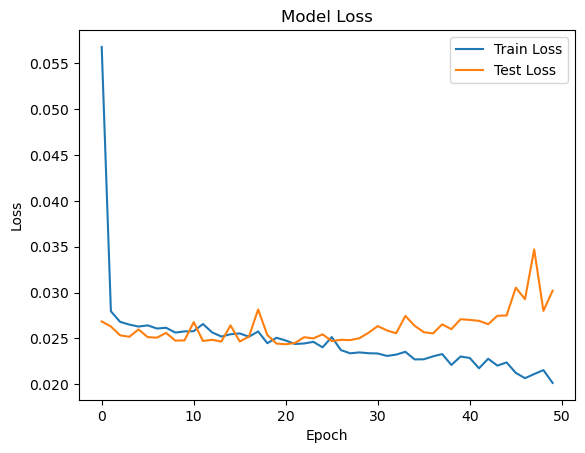

In [19]:
# Plot training history
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [20]:
y_pred = model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 189ms/step


In [21]:
y_pred

array([[0.52641773],
       [0.5214041 ],
       [0.5592507 ],
       [0.51470774],
       [0.5076215 ],
       [0.55048203],
       [0.4954287 ],
       [0.489744  ],
       [0.5211944 ],
       [0.5975867 ],
       [0.64111596],
       [0.53667843],
       [0.52739495],
       [0.45412353],
       [0.49635226],
       [0.4674316 ],
       [0.46829358],
       [0.48419365],
       [0.43242335],
       [0.45025444],
       [0.45962918],
       [0.42153582],
       [0.42716858],
       [0.43372196],
       [0.4753793 ],
       [0.49944627],
       [0.5559427 ],
       [0.5229064 ],
       [0.53453684],
       [0.55288553],
       [0.46053892],
       [0.3876786 ],
       [0.35782355],
       [0.36162612],
       [0.37537998],
       [0.41206443],
       [0.43286788],
       [0.45007402],
       [0.51861346],
       [0.47538745],
       [0.4498332 ],
       [0.48621982],
       [0.48056597],
       [0.45054138],
       [0.39017913],
       [0.48708105],
       [0.44055772],
       [0.465

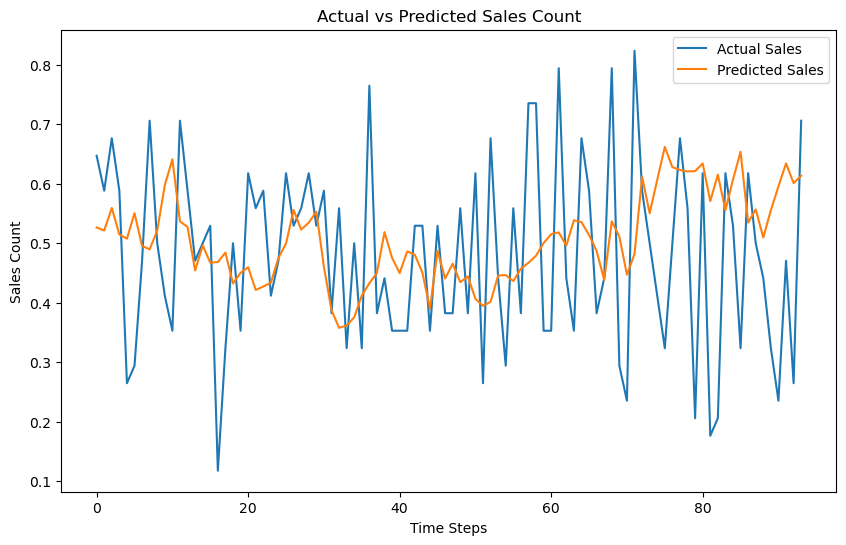

In [22]:
plt.figure(figsize=(10,6))
plt.plot(y_test, label='Actual Sales')
plt.plot(y_pred, label='Predicted Sales')
plt.title('Actual vs Predicted Sales Count')
plt.xlabel('Time Steps')
plt.ylabel('Sales Count')
plt.legend()
plt.show()